## Move-out: Limpieza de datasets
Como bien hemos dicho en el project work plan, queremos responder a la siguiente pregunta:
¿Es verdad que la gente se está yendo de Barcelona a municipios cercanos porque los precios están subiendo demasiado?

Vamos a comprobar esto con los datasets de Telefónica (en los cuales analizaremos las entradas y salidas de Barcelona Ciudad en cada día) y también vamos a comprobar si los precios han aumentado verdaderamente o no. Para esto último, hemos encontrado datasets interesantes en el portal Open Data BCN:https://opendata-ajuntament.barcelona.cat/data/es/organization/poblacio

Como todavía no tenemos los datos de Telefónica, vamos a empezar analizando y limpiando los datos del precio de las viviendas y los alquileres.

# Evolución de los precios de compra y alquiler en Barcelona

Vamos a limpiar y comparar las series de alquiler y compraventa para Barcelona ciudad y sus barrios. La comparación común utiliza los años completos **2023–2025**. También se muestra la serie histórica disponible de alquiler y el detalle trimestral de compraventas de 2025.

**Medidas distintas:** la compraventa se expresa en €/m² construido y el alquiler en €/m²/mes. No se comparan sus valores absolutos, sino su evolución porcentual. Se conserva 2026 en los datos limpios, pero se excluye de las comparaciones por ser un año en curso.

In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd
from openpyxl import load_workbook

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)

# Admite ejecutar desde la carpeta del proyecto o desde su raíz.
possible_roots = [Path.cwd(), Path.cwd() / "Move-OUT", Path.cwd().parent / "Move-OUT"]
PROJECT_ROOT = next((root for root in possible_roots if (root / "datasets").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("No se encuentra la carpeta 'datasets'. Ejecuta desde el proyecto Move-OUT.")

DATA_DIR = PROJECT_ROOT / "datasets"
RENT_FILE = DATA_DIR / "datos_alquiler.csv"
if not RENT_FILE.is_file():
    raise FileNotFoundError(f"Falta el fichero de alquiler: {RENT_FILE}")

SALES_SOURCES = {
    2023: (DATA_DIR / "BCN_acumulat_2023.csv", "4t23_acum"),
    2024: (DATA_DIR / "BCN_acumulat_2024.csv", "4t24_acum"),
    2025: (DATA_DIR / "BCN_acumulat_2025.csv", "2025"),
}
for year, (path, _) in SALES_SOURCES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Falta el fichero de compraventas de {year}: {path}")

print(f"Carpeta de datos: {DATA_DIR.resolve()}")
print(f"CSV de alquiler: {RENT_FILE.name}")

Carpeta de datos: C:\Users\nilmo\Desktop\4t-Curs-UPF\1r-Trimestre\Gestió de Projectes\Move-OUT\datasets
CSV de alquiler: datos_alquiler.csv


## 1. Limpieza de compraventas

Leemos las hojas anuales de cada Excel. En los tres ficheros, Barcelona está en la fila 6, los distritos en las filas 9–18 y los barrios en las filas 21–93. Se conservan el número de compraventas, la superficie media y el precio total de compraventa por m² construido.

In [2]:
import csv
import pandas as pd

def to_number(value):
    if value is None or (isinstance(value, str) and value.strip() in {"", "-", ".."}):
        return pd.NA
    if isinstance(value, str):
        # Elimina puntos de millares (ex: 4.370,96 -> 4370,96) y reemplaza la coma decimal por punto (-> 4370.96)
        value = value.strip().replace(".", "").replace(",", ".")
    return pd.to_numeric(value, errors="coerce")

def extract_sales_csv(path, year, period):
    with open(path, mode="r", encoding="utf-8", errors="ignore") as f:
        reader = list(csv.reader(f))
    
    # Filas absolutas en el CSV (índice 0):
    # Fila 6 -> índice 5 (Barcelona*)
    # Filas 9-18 -> índices 8 a 17 (Districtes 1 a 10)
    # Filas 21-93 -> índices 20 a 92 (Barris 1 a 73)
    rows = [(5, "Ciudad")]
    rows += [(r, "Distrito") for r in range(8, 18)]
    rows += [(r, "Barrio") for r in range(20, 93)]
    
    records = []
    for row_idx, level in rows:
        if row_idx >= len(reader):
            continue
        row = reader[row_idx]
        
        # Validar que la fila no esté vacía ni sea una cabecera de sección
        if len(row) < 19 or not row[1].strip() or row[1].strip() in {"Districtes municipals", "Barris"}:
            continue
            
        records.append({
            "año": year,
            "periodo": period,
            "nivel": level,
            "territorio": str(row[1]).strip().rstrip("*").strip(),
            "codigo": row[0].strip() if row[0] else None,
            "compraventas": to_number(row[5]),
            "superficie_media_m2": to_number(row[10]),
            "precio_compra_eur_m2": to_number(row[18]),
        })
    return records

# Procesamiento de las fuentes CSV
annual_records = []
for year, (path, _) in SALES_SOURCES.items():
    # Usamos la función adaptada para archivos CSV
    annual_records.extend(extract_sales_csv(path, year, "Anual"))

sales_annual = pd.DataFrame(annual_records)

# Aseguramos que los tipos de columna sean numéricos
for column in ["compraventas", "superficie_media_m2", "precio_compra_eur_m2"]:
    sales_annual[column] = pd.to_numeric(sales_annual[column], errors="coerce")

# Limpieza de valores <= 0
sales_annual.loc[sales_annual["precio_compra_eur_m2"] <= 0, "precio_compra_eur_m2"] = pd.NA
sales_annual.loc[sales_annual["superficie_media_m2"] <= 0, "superficie_media_m2"] = pd.NA

# Validaciones de integridad
assert set(sales_annual["año"].unique()) == {2023, 2024, 2025}
assert not sales_annual.duplicated(["año", "nivel", "territorio"]).any()

print(f"Registros anuales limpios: {len(sales_annual)}")
display(sales_annual.groupby(["año", "nivel"], as_index=False).agg(
    territorios=("territorio", "nunique"),
    precios_disponibles=("precio_compra_eur_m2", "count"),
    compraventas=("compraventas", "sum"),
))

Registros anuales limpios: 252


,año,nivel,territorios,precios_disponibles,compraventas
0,2023,Barrio,73,72,14774
1,2023,Ciudad,1,1,14899
2,2023,Distrito,10,10,14774
3,2024,Barrio,73,71,15691
4,2024,Ciudad,1,1,15800
5,2024,Distrito,10,10,15691
6,2025,Barrio,73,71,15869
7,2025,Ciudad,1,1,15960
8,2025,Distrito,10,10,15869


## 2. Limpieza del alquiler

El CSV `datos_alquiler.csv` contiene precios de alquiler en €/m²/mes. Utiliza codificación occidental, separador `;`, coma decimal y guiones para valores no disponibles. Se transforma de formato ancho (una columna por año) a formato largo y se clasifican ciudad, distritos, barrios y referencias territoriales (Catalunya y área metropolitana), que no se mezclan con los barrios.

In [3]:
import re
import unicodedata
import pandas as pd

# 1. Carga del CSV
rent_wide = pd.read_csv(
    RENT_FILE,
    sep=";",
    encoding="latin1",
    dtype={"Territorio": "string"},
    na_values=["-", ""],
)

rent_wide.columns = rent_wide.columns.astype(str).str.strip()
year_columns = [col for col in rent_wide.columns if re.fullmatch(r"\d{4}", col)]

if "Territorio" not in rent_wide.columns or not year_columns:
    raise ValueError("No se reconoce la estructura esperada del CSV de alquiler.")

# 2. Transformación a formato largo (melt)
rent_long = rent_wide.melt(
    id_vars="Territorio",
    value_vars=year_columns,
    var_name="año",
    value_name="alquiler_eur_m2",
).rename(columns={"Territorio": "territorio"})

rent_long["territorio"] = rent_long["territorio"].astype("string").str.strip()
rent_long["año"] = rent_long["año"].astype(int)

# Limpieza numérica de precios
rent_long["alquiler_eur_m2"] = pd.to_numeric(
    rent_long["alquiler_eur_m2"].astype("string").str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    errors="coerce",
)
rent_long.loc[rent_long["alquiler_eur_m2"] <= 0, "alquiler_eur_m2"] = pd.NA


# 3. Funciones de clave y clasificación de territorio
def place_key(value):
    value = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode("ascii")
    value = re.sub(r"\s*\((?:barrio|distrito)\)$", "", value, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", value.strip().casefold())

district_names = sales_annual.loc[sales_annual["nivel"].eq("Distrito"), "territorio"].drop_duplicates().tolist()
district_lookup = {place_key(name): name for name in district_names}
district_lookup[place_key("Sant Andreu (Distrito)")] = "Sant Andreu"
district_lookup[place_key("Sant Marti")] = "Sant Martí"

rent_aliases = {
    place_key("el Poble Sec - AEI Parc Montjuïc"): place_key("el Poble Sec - Parc Montjuïc"),
    place_key("la Marina del Prat Vermell - AEI Zona Franca"): place_key("la Marina del Prat Vermell - Zona Franca"),
}

def canonical_key(value):
    key = place_key(value)
    return rent_aliases.get(key, key)

def classify_rent_place(value):
    raw_val = str(value).strip()
    label = raw_val.casefold()
    key = place_key(raw_val)

    if key == place_key("Barcelona"):
        return "Ciudad"
    if key in {place_key("Catalunya"), place_key("Metropolità de Barcelona")}:
        return "Referencia"
    if "(barrio)" in label or label.endswith(" (barrio)"):
        return "Barrio"
    if "(distrito)" in label or label.endswith(" (distrito)"):
        return "Distrito"

    # Caso específico para diferenciar 'Les Corts' (Distrito) de 'les Corts' (Barrio)
    if key == place_key("les Corts"):
        return "Distrito" if raw_val == "Les Corts" else "Barrio"

    if key in district_lookup:
        return "Distrito"

    return "Barrio"


# 4. Asignación y validación final
rent_long["nivel"] = rent_long["territorio"].map(classify_rent_place)
rent_long["clave_territorio"] = rent_long["territorio"].map(canonical_key)

# Verificación de duplicados
assert not rent_long.duplicated(["año", "nivel", "clave_territorio"]).any(), "¡Hay duplicados en clave_territorio por nivel y año!"

print(f"Registros de alquiler limpios: {len(rent_long)}")
display(rent_long.groupby(["nivel", "año"], as_index=False).agg(
    territorios=("territorio", "nunique"),
    valores_disponibles=("alquiler_eur_m2", "count"),
    alquiler_medio_eur_m2=("alquiler_eur_m2", "mean"),
).query("año in [2000, 2023, 2024, 2025, 2026]"))

Registros de alquiler limpios: 2268


,nivel,año,territorios,valores_disponibles,alquiler_medio_eur_m2
0,Barrio,2000,73,0,<NA>
23,Barrio,2023,73,71,15.216338
24,Barrio,2024,73,72,15.12125
25,Barrio,2025,73,73,15.606027
26,Barrio,2026,73,68,16.178382
27,Ciudad,2000,1,1,6.0
50,Ciudad,2023,1,1,16.1
51,Ciudad,2024,1,1,16.13
52,Ciudad,2025,1,1,16.67
53,Ciudad,2026,1,1,16.89


## 3. ¿Han subido los precios en Barcelona?

Vamos a calcular el cambio entre 2023 y 2025 para las dos variables en los años comunes. Para el alquiler también calcularemos el cambio entre su primer y último año con datos de Barcelona. Los porcentajes describen cambios de las medias publicadas; no son una medida ajustada por inflación.

In [4]:
ANALYSIS_START = 2023
ANALYSIS_END = 2025

city_sales = sales_annual.query("nivel == 'Ciudad'").set_index("año")["precio_compra_eur_m2"].sort_index()
city_rent = rent_long.query("nivel == 'Ciudad'").set_index("año")["alquiler_eur_m2"].sort_index()


def percent_change(series, start_year, end_year):
    start = series.get(start_year, pd.NA)
    end = series.get(end_year, pd.NA)
    if pd.isna(start) or pd.isna(end) or start == 0:
        return pd.NA
    return (end / start - 1) * 100


first_rent_year = int(city_rent.dropna().index.min())
last_closed_rent_year = min(ANALYSIS_END, int(city_rent.dropna().index.max()))
city_summary = pd.DataFrame([
    {
        "indicador": "Compraventa (€/m² construido)",
        "valor_inicial": city_sales.get(ANALYSIS_START),
        "valor_final": city_sales.get(ANALYSIS_END),
        "periodo": f"{ANALYSIS_START}–{ANALYSIS_END}",
        "variacion_pct": percent_change(city_sales, ANALYSIS_START, ANALYSIS_END),
    },
    {
        "indicador": "Alquiler (€/m²/mes)",
        "valor_inicial": city_rent.get(ANALYSIS_START),
        "valor_final": city_rent.get(ANALYSIS_END),
        "periodo": f"{ANALYSIS_START}–{ANALYSIS_END}",
        "variacion_pct": percent_change(city_rent, ANALYSIS_START, ANALYSIS_END),
    },
    {
        "indicador": "Alquiler histórico (€/m²/mes)",
        "valor_inicial": city_rent.get(first_rent_year),
        "valor_final": city_rent.get(last_closed_rent_year),
        "periodo": f"{first_rent_year}–{last_closed_rent_year}",
        "variacion_pct": percent_change(city_rent, first_rent_year, last_closed_rent_year),
    },
])
display(city_summary.round({"valor_inicial": 2, "valor_final": 2, "variacion_pct": 1}))

aligned_years = list(range(ANALYSIS_START, ANALYSIS_END + 1))
city_index = pd.DataFrame({
    "Año": aligned_years,
    "Compraventa (base 2023 = 100)": [
        city_sales.get(year) / city_sales.get(ANALYSIS_START) * 100 for year in aligned_years
    ],
    "Alquiler (base 2023 = 100)": [
        city_rent.get(year) / city_rent.get(ANALYSIS_START) * 100 for year in aligned_years
    ],
}).set_index("Año")
display(city_index.round(1))

,indicador,valor_inicial,valor_final,periodo,variacion_pct
0,Compraventa (€/m² construido),4370.96,4797.02,2023–2025,9.7
1,Alquiler (€/m²/mes),16.10,16.67,2023–2025,3.5
2,Alquiler histórico (€/m²/mes),6.00,16.67,2000–2025,177.8


,Compraventa (base 2023 = 100),Alquiler (base 2023 = 100)
Año,,
2023,100.0,100.0
2024,102.5,100.2
2025,109.7,103.5


## 4. Evolución por barrio

Para cada barrio con dato válido en ambos extremos, comparamos 2023 con 2025.Normalizamos acentos y dos diferencias conocidas de nomenclatura entre fuentes para cruzar los registros. Los barrios sin precio publicado o sin valor de alquiler quedan fuera del cálculo correspondiente.

In [5]:
import pandas as pd

# 1. Filtrado y pivotado de Compraventa
sales_barrio = sales_annual.query("nivel == 'Barrio'").copy()
sales_barrio["clave_territorio"] = sales_barrio["territorio"].map(canonical_key)
sales_barrio_wide = sales_barrio.pivot(
    index="clave_territorio", columns="año", values="precio_compra_eur_m2"
)

# 2. Filtrado y pivotado de Alquiler
rent_barrio = rent_long.query("nivel == 'Barrio'").copy()
rent_barrio["clave_territorio"] = rent_barrio["territorio"].map(canonical_key)
rent_barrio_wide = rent_barrio.pivot(
    index="clave_territorio", columns="año", values="alquiler_eur_m2"
)

# 3. Mapeo único de nombres oficiales de los barrios
names_lookup = (
    pd.concat([sales_barrio, rent_barrio])
    .sort_values("año")
    .drop_duplicates("clave_territorio", keep="last")
    .set_index("clave_territorio")["territorio"]
)

# 4. Creación del DataFrame de crecimiento con el índice unificado
all_keys = sales_barrio_wide.index.union(rent_barrio_wide.index)
barrio_growth = pd.DataFrame(index=all_keys)

barrio_growth["barrio"] = barrio_growth.index.map(names_lookup)

# Compraventa (€/m²)
barrio_growth["compra_2023_eur_m2"] = sales_barrio_wide.get(2023)
barrio_growth["compra_2025_eur_m2"] = sales_barrio_wide.get(2025)
barrio_growth["compra_variacion_pct"] = (
    (barrio_growth["compra_2025_eur_m2"] / barrio_growth["compra_2023_eur_m2"]) - 1
) * 100

# Alquiler (€/m²)
barrio_growth["alquiler_2023_eur_m2"] = rent_barrio_wide.get(2023)
barrio_growth["alquiler_2025_eur_m2"] = rent_barrio_wide.get(2025)
barrio_growth["alquiler_variacion_pct"] = (
    (barrio_growth["alquiler_2025_eur_m2"] / barrio_growth["alquiler_2023_eur_m2"]) - 1
) * 100

barrio_growth = barrio_growth.reset_index(drop=True)

# 5. Ránkings
sales_rank = barrio_growth.dropna(subset=["compra_variacion_pct"]).sort_values("compra_variacion_pct", ascending=False)
rent_rank = barrio_growth.dropna(subset=["alquiler_variacion_pct"]).sort_values("alquiler_variacion_pct", ascending=False)

print(f"Barrios comparables en compraventa: {len(sales_rank)}")
print(f"Barrios comparables en alquiler: {len(rent_rank)}")

print("\nMayores subidas de compraventa (%):")
display(sales_rank[["barrio", "compra_2023_eur_m2", "compra_2025_eur_m2", "compra_variacion_pct"]].head(10).round(1))

print("\nMayores subidas de alquiler (%):")
display(rent_rank[["barrio", "alquiler_2023_eur_m2", "alquiler_2025_eur_m2", "alquiler_variacion_pct"]].head(10).round(1))

print("\nMayores bajadas de compraventa (%):")
display(sales_rank.tail(10).sort_values("compra_variacion_pct")[["barrio", "compra_variacion_pct"]].round(1))

print("\nMayores bajadas de alquiler (%):")
display(rent_rank.tail(10).sort_values("alquiler_variacion_pct")[["barrio", "alquiler_variacion_pct"]].round(1))

Barrios comparables en compraventa: 69
Barrios comparables en alquiler: 71

Mayores subidas de compraventa (%):


,barrio,compra_2023_eur_m2,compra_2025_eur_m2,compra_variacion_pct
70,Vallbona,1464.9,2631.0,79.6
48,la Verneda i la Pau,2283.6,3981.2,74.3
30,la Clota,3153.8,4700.4,49.0
56,Pedralbes,5650.2,7486.2,32.5
57,Porta,2724.0,3585.4,31.6
26,Hostafrancs,3347.0,4319.8,29.1
35,la Marina de Port,3386.1,4335.3,28.0
55,Navas,3428.6,4353.2,27.0
73,Verdun,2392.8,3031.2,26.7
67,Sants - Badal,3462.9,4367.3,26.1



Mayores subidas de alquiler (%):


,barrio,alquiler_2023_eur_m2,alquiler_2025_eur_m2,alquiler_variacion_pct
69,Torre Baró,7.7,10.4,34.2
30,la Clota,15.5,20.2,30.3
37,la Marina del Prat Vermell - AEI Zona Franca,13.4,17.4,29.6
28,la Barceloneta,19.0,22.7,19.6
5,Diagonal Mar i el Front Marítim del Poblenou,18.8,22.4,19.0
54,Montbau,13.8,15.5,12.3
63,Sant Gervasi - la Bonanova,17.8,19.2,8.0
43,la Salut,15.3,16.5,7.4
1,Can Baró,15.0,16.0,7.1
65,"Sant Pere, Santa Caterina i la Ribera",17.4,18.6,6.9



Mayores bajadas de compraventa (%):


,barrio,compra_variacion_pct
46,la Trinitat Vella,-21.8
61,Sant Genís dels Agudells,-7.5
63,Sant Gervasi - la Bonanova,-3.0
68,Sarrià,-0.5
18,el Parc i la Llacuna del Poblenou,1.5
8,el Besòs i el Maresme,3.0
43,la Salut,3.4
7,el Barri Gòtic,3.4
38,la Maternitat i Sant Ramon,4.3
72,"Vallvidrera, el Tibidabo i les Planes",4.7



Mayores bajadas de alquiler (%):


,barrio,alquiler_variacion_pct
29,la Bordeta,-13.4
48,la Verneda i la Pau,-13.1
0,Baró de Viver,-8.5
45,la Trinitat Nova,-7.9
3,Canyelles,-7.2
32,la Font d'en Fargues,-5.8
16,el Fort Pienc,-3.3
42,la Sagrera,-3.2
73,Verdun,-2.2
4,Ciutat Meridiana,-1.8


## 5. Gráficos y conclusión

El índice con base 2023 = 100 muestra si alquiler y compraventa han crecido a ritmos distintos, aunque el alquiler ahora está expresado en €/m²/mes. Los gráficos por barrio muestran las diez mayores subidas de cada indicador.

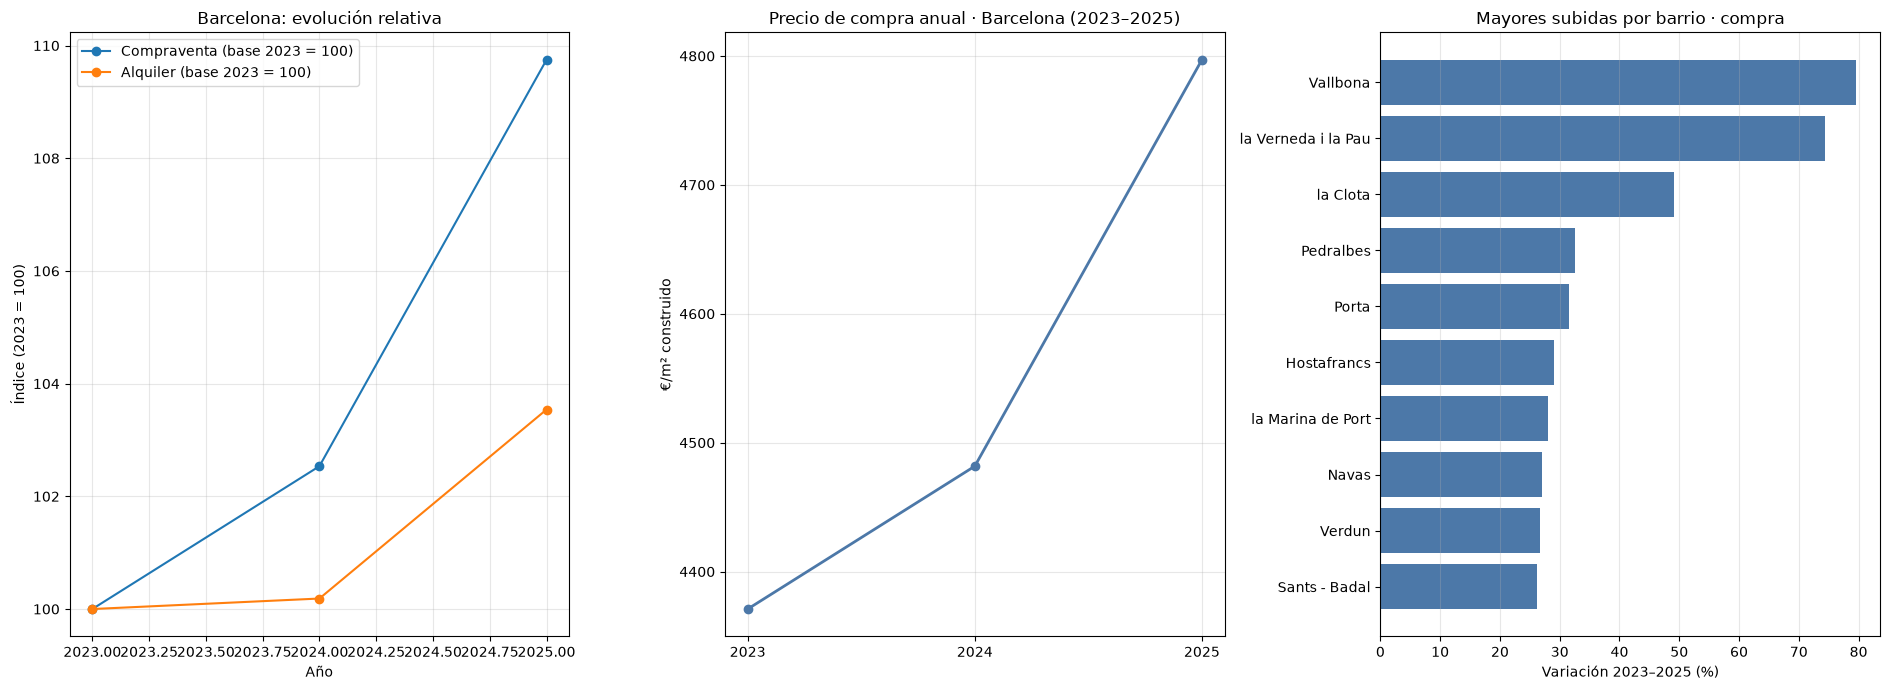

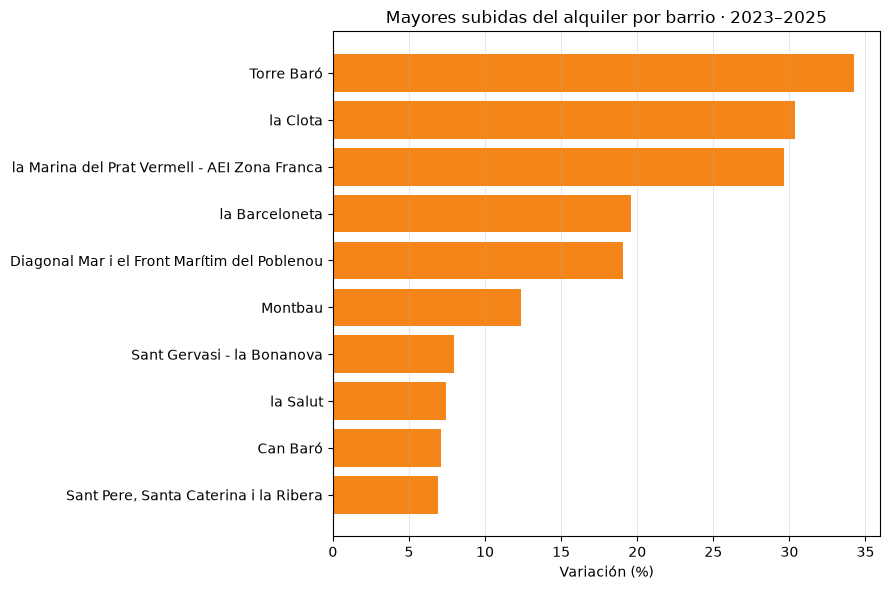

Conclusión ciudad:
- Compraventa (€/m² construido): ha subido un 9.7% entre 2023–2025.
- Alquiler (€/m²/mes): ha subido un 3.5% entre 2023–2025.

Limitaciones: el precio de compraventa es una media anual de operaciones registradas; el alquiler es una media anual publicada. Los cambios en el tipo y volumen de viviendas contratadas pueden influir en ambas medias.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(19, 7))

# 1. Evolució relativa de la ciutat (Índex 2023 = 100)
city_index.plot(marker="o", ax=axes[0])
axes[0].set_title("Barcelona: evolución relativa")
axes[0].set_ylabel("Índice (2023 = 100)")
axes[0].grid(alpha=0.3)

# 2. CANVIAT: Preu de compra ANUAL a Barcelona (2023-2025)
city_annual = sales_annual.query("nivel == 'Ciudad'").sort_values("año")
axes[1].plot(city_annual["año"].astype(str), city_annual["precio_compra_eur_m2"], marker="o", color="#4C78A8", linewidth=2)
axes[1].set_title("Precio de compra anual · Barcelona (2023–2025)")
axes[1].set_ylabel("€/m² construido")
axes[1].grid(alpha=0.3)

# 3. Majors pujades de compra per barri
top_sale = sales_rank.head(10).sort_values("compra_variacion_pct")
axes[2].barh(top_sale["barrio"], top_sale["compra_variacion_pct"], color="#4C78A8")
axes[2].set_title("Mayores subidas por barrio · compra")
axes[2].set_xlabel("Variación 2023–2025 (%)")
axes[2].grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Gràfica independent de lloguer per barris
top_rent = rent_rank.head(10).sort_values("alquiler_variacion_pct")
plt.figure(figsize=(9, 6))
plt.barh(top_rent["barrio"], top_rent["alquiler_variacion_pct"], color="#F58518")
plt.title("Mayores subidas del alquiler por barrio · 2023–2025")
plt.xlabel("Variación (%)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Conclusión ciudad:")
for _, row in city_summary.iloc[:2].iterrows():
    direction = "ha subido" if row["variacion_pct"] > 0 else "ha bajado" if row["variacion_pct"] < 0 else "se ha mantenido"
    print(f"- {row['indicador']}: {direction} un {row['variacion_pct']:.1f}% entre {row['periodo']}.")

print("\nLimitaciones: el precio de compraventa es una media anual de operaciones registradas; el alquiler es una media anual publicada. Los cambios en el tipo y volumen de viviendas contratadas pueden influir en ambas medias.")